In [ ]:
import pandas as pd
import numpy as np

# 1. Load the dataset (updated file name with spaces)
df = pd.read_csv("Bike Rental Demand.csv")
print(df.head())
print("Shape:", df.shape)
print(df.dtypes)


   season  yr  mnth  hr  holiday  weekday  workingday  weathersit  temp  \
0       1   0     1   0        0        6           0           1  0.24   
1       1   0     1   1        0        6           0           1  0.22   
2       1   0     1   2        0        6           0           1  0.22   
3       1   0     1   3        0        6           0           1  0.24   
4       1   0     1   4        0        6           0           1  0.24   

    atemp   hum  windspeed  registered  cnt  
0  0.2879  0.81        0.0          13   16  
1  0.2727  0.80        0.0          32   40  
2  0.2727  0.80        0.0          27   32  
3  0.2879  0.75        0.0          10   13  
4  0.2879  0.75        0.0           1    1  
Shape: (17379, 14)
season          int64
yr              int64
mnth            int64
hr              int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed   

In [ ]:
df["season"] = df["season"].map({
    1: "Spring",
    2: "Summer",
    3: "Fall",
    4: "Winter"
})

df["weathersit"] = df["weathersit"].map({
    1: "Clear",
    2: "Mist",
    3: "Light Rain/Snow",
    4: "Heavy Rain/Snow"
})

df.head()

,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,registered,cnt
0,Spring,0,1,0,0,6,0,Clear,0.24,0.2879,0.81,0.0,13,16
1,Spring,0,1,1,0,6,0,Clear,0.22,0.2727,0.80,0.0,32,40
2,Spring,0,1,2,0,6,0,Clear,0.22,0.2727,0.80,0.0,27,32
3,Spring,0,1,3,0,6,0,Clear,0.24,0.2879,0.75,0.0,10,13
4,Spring,0,1,4,0,6,0,Clear,0.24,0.2879,0.75,0.0,1,1


In [ ]:
# 2. Check for missing values and duplicates
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
print(df[df.duplicated(keep=False)])

Missing values:
 season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
registered    0
cnt           0
dtype: int64
Duplicate rows: 2
       season  yr  mnth  hr  holiday  weekday  workingday weathersit  temp  \
7958   Winter   0    12   6        0        6           0      Clear  0.24   
8126   Winter   0    12   6        0        6           0      Clear  0.24   
13559    Fall   1     7   4        0        2           1      Clear  0.66   
13727    Fall   1     7   4        0        2           1      Clear  0.66   

        atemp   hum  windspeed  registered  cnt  
7958   0.2576  0.65     0.1045          10   11  
8126   0.2576  0.65     0.1045          10   11  
13559  0.6061  0.83     0.0896           6    6  
13727  0.6061  0.83     0.0896           6    6  


In [ ]:
# Remove unwanted / redundant columns

columns_to_drop = ["atemp", "registered"]

df = df.drop(columns=columns_to_drop)

print("Remaining columns:", list(df.columns))
print("New shape:", df.shape)

Remaining columns: ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'hum', 'windspeed', 'cnt']
New shape: (17379, 12)


In [ ]:
print(df.describe())

for col in ["season", "yr", "mnth", "hr", "holiday", "weekday", "workingday", "weathersit"]:
    print(col, "->", sorted(df[col].unique()))

print("temp range:", df.temp.min(), "-", df.temp.max())
print("hum range:", df.hum.min(), "-", df.hum.max())
print("windspeed range:", df.windspeed.min(), "-", df.windspeed.max())

# hum == 0 is physically unrealistic (0% humidity never really happens)
print("Rows with hum == 0:", (df.hum == 0).sum())
print(df[df.hum == 0].head())

                 yr          mnth            hr       holiday       weekday  \
count  17379.000000  17379.000000  17379.000000  17379.000000  17379.000000   
mean       0.502561      6.537775     11.546752      0.028770      3.003683   
std        0.500008      3.438776      6.914405      0.167165      2.005771   
min        0.000000      1.000000      0.000000      0.000000      0.000000   
25%        0.000000      4.000000      6.000000      0.000000      1.000000   
50%        1.000000      7.000000     12.000000      0.000000      3.000000   
75%        1.000000     10.000000     18.000000      0.000000      5.000000   
max        1.000000     12.000000     23.000000      1.000000      6.000000   

         workingday          temp           hum     windspeed           cnt  
count  17379.000000  17379.000000  17379.000000  17379.000000  17379.000000  
mean       0.682721      0.496987      0.627229      0.190098    189.463088  
std        0.465431      0.192556      0.192930      0

In [ ]:

# 4. Remove duplicate rows
before = df.shape[0]
df = df.drop_duplicates()
print(f"Removed {before - df.shape[0]} duplicate rows -> new shape: {df.shape}")

Removed 2 duplicate rows -> new shape: (17377, 12)


In [ ]:
# 5. Fix invalid hum == 0 readings
df.loc[df["hum"] == 0, "hum"] = np.nan
df["hum"] = df.groupby(["season", "weathersit"])["hum"].transform(lambda x: x.fillna(x.median()))
df["hum"] = df["hum"].fillna(df["hum"].median())  # safety net

print("Remaining hum == 0:", (df["hum"] == 0).sum())
print("Remaining missing hum:", df["hum"].isna().sum())

Remaining hum == 0: 0
Remaining missing hum: 0


In [ ]:
# 7. Final verification
print("Final shape:", df.shape)
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows left:", df.duplicated().sum())
print("hum range now:", df.hum.min(), "-", df.hum.max())

Final shape: (17377, 12)
Total missing values: 0
Duplicate rows left: 0
hum range now: 0.08 - 1.0


In [ ]:

df.to_csv("cleaned_data.csv", index=False)
print("Saved cleaned_data.csv with shape", df.shape)

Saved cleaned_data.csv with shape (17377, 12)


In [ ]:
df.describe()

,yr,mnth,hr,holiday,weekday,workingday,temp,hum,windspeed,cnt
count,17377.000000,17377.000000,17377.000000,17377.000000,17377.000000,17377.000000,17377.000000,17377.000000,17377.000000,17377.000000
mean,0.502561,6.537435,11.547505,0.028774,3.003568,0.682742,0.496993,0.628293,0.190108,189.483916
std,0.500008,3.438722,6.914438,0.167175,2.005744,0.465422,0.192553,0.191814,0.122343,181.387645
min,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.020000,0.080000,0.000000,1.000000
25%,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,0.340000,0.480000,0.104500,40.000000
50%,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,0.500000,0.630000,0.194000,142.000000
75%,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,0.660000,0.780000,0.253700,281.000000
max,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,1.000000,1.000000,0.850700,977.000000


In [ ]:
df.isnull().sum()

,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0
temp,0
hum,0


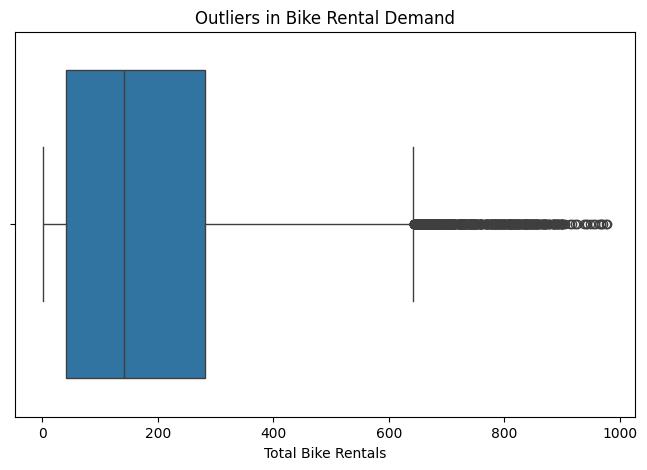

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))

sns.boxplot(x=df["cnt"])

plt.title("Outliers in Bike Rental Demand")
plt.xlabel("Total Bike Rentals")

plt.show()

In [ ]:
Q1 = df["cnt"].quantile(0.25)
Q3 = df["cnt"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df = df[(df["cnt"] >= lower) & (df["cnt"] <= upper)]

print("New dataset shape:", df.shape)

New dataset shape: (16872, 12)


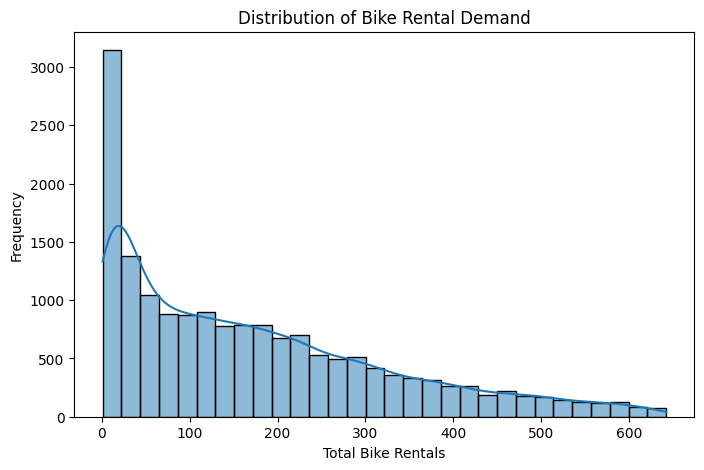

In [ ]:
import pandas as pd

plt.figure(figsize=(8,5))
sns.histplot(df["cnt"], kde=True, bins=30)

plt.title("Distribution of Bike Rental Demand")
plt.xlabel("Total Bike Rentals")
plt.ylabel("Frequency")
plt.show()

In [ ]:
hourly_demand = df.groupby("hr")["cnt"].mean()

hourly_demand

,cnt
hr,
0,53.898072
1,33.375691
2,22.869930
3,11.727403
4,6.353448
5,19.889819
6,76.133978
7,212.064649
8,284.525000


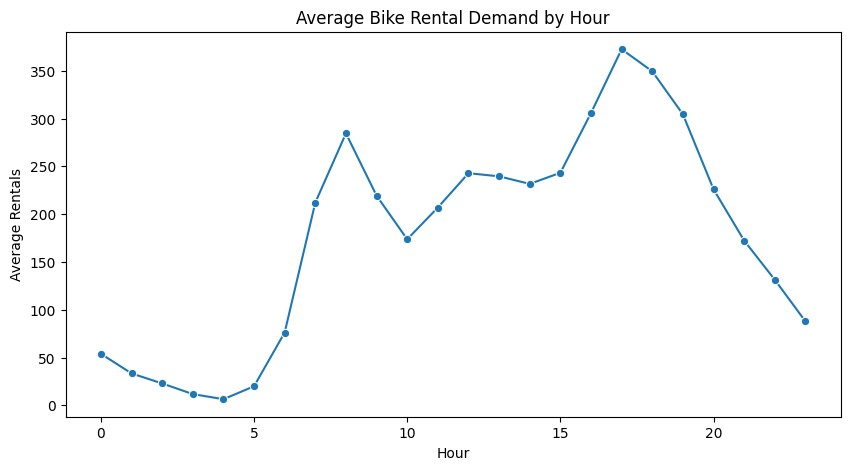

In [ ]:
hourly = df.groupby("hr")["cnt"].mean()

plt.figure(figsize=(10,5))
sns.lineplot(x=hourly.index, y=hourly.values, marker="o")

plt.title("Average Bike Rental Demand by Hour")
plt.xlabel("Hour")
plt.ylabel("Average Rentals")
plt.show()

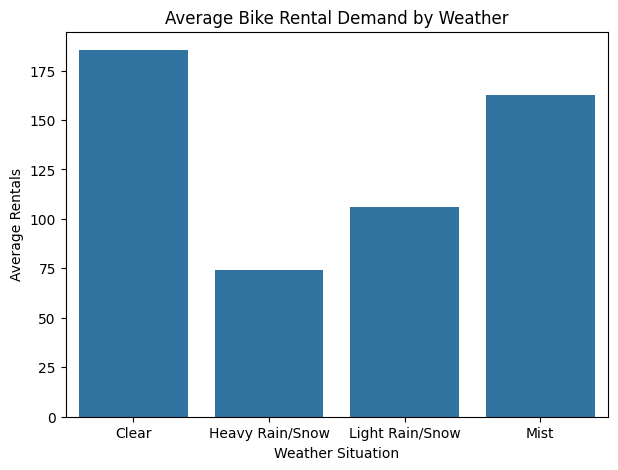

In [ ]:
weather = df.groupby("weathersit")["cnt"].mean()

plt.figure(figsize=(7,5))
sns.barplot(x=weather.index, y=weather.values)

plt.title("Average Bike Rental Demand by Weather")
plt.xlabel("Weather Situation")
plt.ylabel("Average Rentals")
plt.show()

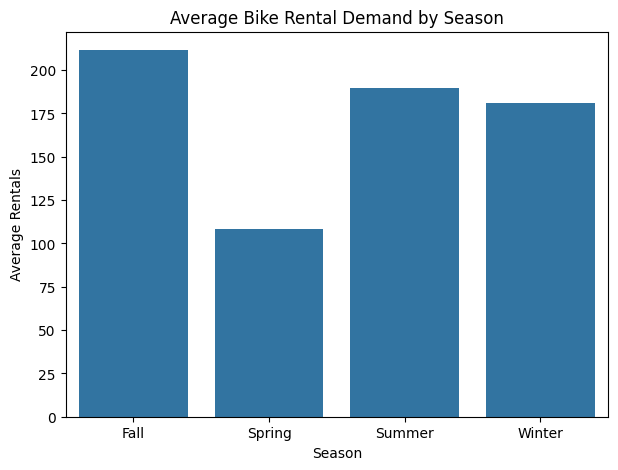

In [ ]:
season = df.groupby("season")["cnt"].mean()

plt.figure(figsize=(7,5))
sns.barplot(x=season.index, y=season.values)

plt.title("Average Bike Rental Demand by Season")
plt.xlabel("Season")
plt.ylabel("Average Rentals")
plt.show()

In [ ]:
monthly_demand = df.groupby("mnth")["cnt"].mean()

monthly_demand

,cnt
mnth,
1,94.424773
2,112.865026
3,141.365344
4,170.952620
5,206.461165
6,218.759246
7,212.468619
8,211.587900
9,204.008185


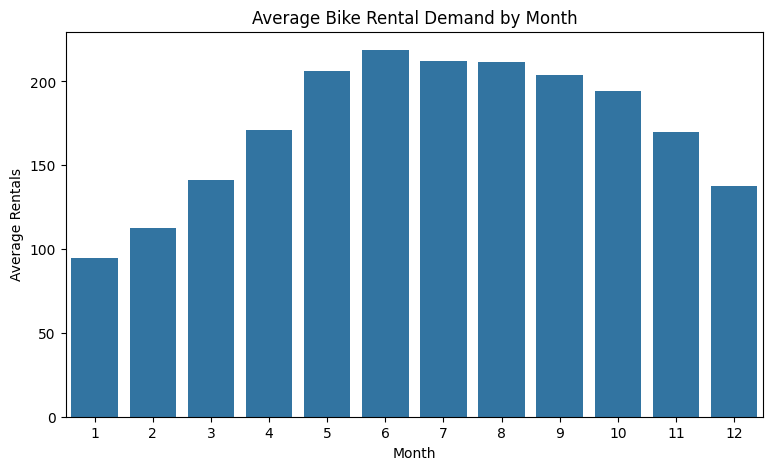

In [ ]:
plt.figure(figsize=(9,5))

sns.barplot(
    x=monthly_demand.index,
    y=monthly_demand.values
)

plt.title("Average Bike Rental Demand by Month")
plt.xlabel("Month")
plt.ylabel("Average Rentals")
plt.show()

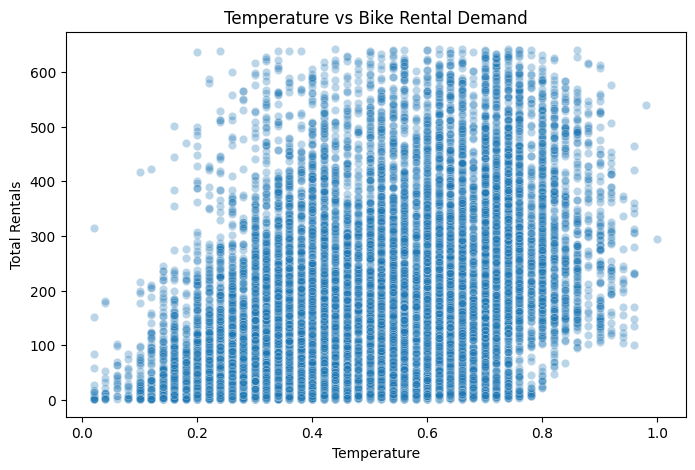

In [ ]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="temp",
    y="cnt",
    alpha=0.3
)

plt.title("Temperature vs Bike Rental Demand")
plt.xlabel("Temperature")
plt.ylabel("Total Rentals")
plt.show()

In [ ]:
print("KEY OBSERVATIONS")
print("-----------------")

print("Peak demand hour:", hourly_demand.idxmax())
print("Highest demand month:", monthly_demand.idxmax())
print("Highest demand season:", season.idxmax())
print("Highest demand weather condition:", weather.idxmax())

# Calculate the correlation matrix
correlation_matrix = df.corr(numeric_only=True)

print("\nHighest correlations with bike demand:")
print(correlation_matrix["cnt"].sort_values(ascending=False).head(6))

KEY OBSERVATIONS
-----------------
Peak demand hour: 17
Highest demand month: 6
Highest demand season: Fall
Highest demand weather condition: Clear

Highest correlations with bike demand:
cnt          1.000000
hr           0.420786
temp         0.401609
yr           0.191584
mnth         0.116240
windspeed    0.097715
Name: cnt, dtype: float64


In [ ]:
cat_cols = ["yr", "mnth", "hr", "holiday", "weekday", "workingday"]
for c in cat_cols:
    df[c] = df[c].astype(int)

num_cols = ["temp", "hum", "windspeed"]
for c in num_cols:
    df[c] = df[c].astype(float)

df["cnt"] = df["cnt"].astype(int)

print(df.dtypes)

season         object
yr              int64
mnth            int64
hr              int64
holiday         int64
weekday         int64
workingday      int64
weathersit     object
temp          float64
hum           float64
windspeed     float64
cnt             int64
dtype: object


In [ ]:
df.to_csv("cleaned_data_final.csv", index=False)

print("Final cleaned dataset saved.")
print("Final shape:", df.shape)

Final cleaned dataset saved.
Final shape: (16872, 12)


In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("cleaned_data_final.csv")

print(df.shape)
print(df.columns.tolist())

(16872, 12)
['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'hum', 'windspeed', 'cnt']


In [ ]:
X = df.drop(columns=["cnt"]).copy()

y = df["cnt"].copy()


print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (16872, 11)
y Shape: (16872,)


In [ ]:
categorical_features = [
    "season",
    "yr",
    "mnth",
    "hr",
    "holiday",
    "weekday",
    "workingday",
    "weathersit"
]

numerical_features = [
    "temp",
    "hum",
    "windspeed"
]

print("Categorical Features:", categorical_features)
print("Numerical Features:", numerical_features)

Categorical Features: ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit']
Numerical Features: ['temp', 'hum', 'windspeed']


In [ ]:
from sklearn.model_selection import train_test_split
X_encoded = pd.get_dummies(X, columns=categorical_features, drop_first=True)


X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (13497, 52)
X_test shape: (3375, 52)
y_train shape: (13497,)
y_test shape: (3375,)


In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train[numerical_features])
X_test_scaled = scaler.transform(X_test[numerical_features])

print("Scaling Complete")
print("Training Data Size:", X_train_scaled.shape)
print("Test Data Size:", X_test_scaled.shape)

Scaling Complete
Training Data Size: (13497, 3)
Test Data Size: (3375, 3)


In [ ]:
X_train_processed = X_train.copy()
X_test_processed = X_test.copy()

In [ ]:
X_train_processed[numerical_features] = X_train_scaled
X_test_processed[numerical_features] = X_test_scaled

In [ ]:
display(X_train_processed.head())
display(X_test_processed.head())

print("X_train_processed shape:", X_train_processed.shape)
print("X_test_processed shape:", X_test_processed.shape)

,temp,hum,windspeed,season_Spring,season_Summer,season_Winter,yr_1,mnth_2,mnth_3,mnth_4,...,weekday_1,weekday_2,weekday_3,weekday_4,weekday_5,weekday_6,workingday_1,weathersit_Heavy Rain/Snow,weathersit_Light Rain/Snow,weathersit_Mist
16313,-0.481480,1.243445,-0.447748,False,False,True,True,False,False,False,...,False,False,False,False,False,True,False,False,False,True
10615,0.035722,1.609520,0.891370,False,True,False,True,False,True,False,...,False,False,False,False,False,True,False,False,True,False
2128,-0.274599,-1.580564,0.891370,False,True,False,False,False,False,True,...,False,False,False,False,False,False,False,False,False,False
702,-1.309003,0.615887,-1.543019,True,False,False,False,True,False,False,...,False,True,False,False,False,False,True,False,False,True
12084,1.690767,-0.377746,0.891370,False,True,False,True,False,False,False,...,True,False,False,False,False,False,False,False,False,False


,temp,hum,windspeed,season_Spring,season_Summer,season_Winter,yr_1,mnth_2,mnth_3,mnth_4,...,weekday_1,weekday_2,weekday_3,weekday_4,weekday_5,weekday_6,workingday_1,weathersit_Heavy Rain/Snow,weathersit_Light Rain/Snow,weathersit_Mist
13278,0.552923,1.295741,0.526008,False,False,False,True,False,False,False,...,False,False,False,False,False,True,False,False,True,False
14079,0.656364,1.295741,-1.543019,False,False,False,True,False,False,False,...,True,False,False,False,False,False,True,False,False,False
15206,0.242602,1.609520,-0.690779,False,False,True,True,False,False,False,...,False,False,False,False,True,False,True,False,False,True
6307,0.759804,1.034259,-1.543019,False,False,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
14661,0.139162,-0.796117,-1.543019,False,False,True,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False


X_train_processed shape: (13497, 52)
X_test_processed shape: (3375, 52)


In [ ]:
print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

print("\nMissing values in training data:",
      X_train_processed.isnull().sum().sum())

print("Missing values in testing data:",
      X_test_processed.isnull().sum().sum())

Training data shape: (13497, 52)
Testing data shape: (3375, 52)

Missing values in training data: 0
Missing values in testing data: 0


In [ ]:
X_train_processed.to_csv("X_train_processed.csv", index=False)
X_test_processed.to_csv("X_test_processed.csv", index=False)

y_train.to_csv("y_train.csv", index=False)
y_test.to_csv("y_test.csv", index=False)

print("Processed data saved successfully!")

Processed data saved successfully!


In [ ]:
import joblib

joblib.dump(scaler, "scaler.pkl")

print("Scaler saved successfully!")

Scaler saved successfully!


In [ ]:
#  ML Model & Evaluation
from sklearn.linear_model import LinearRegression,Ridge,Lasso,ElasticNet
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.feature_selection import RFE
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score

In [ ]:
#Multiple Linear Regression
model=LinearRegression()

model.fit(X_train_processed,y_train)

y_pred=model.predict(X_test_processed)

mae=mean_absolute_error(y_test,y_pred)
rmse=np.sqrt(mean_squared_error(y_test,y_pred))
r2=r2_score(y_test,y_pred)

print("Multiple Linear Regression")
print("RMSE : ",round(rmse,2))
print("MAE : ",round(mae,2))
print("R2 : ",round(r2,2))
rmse_linear=rmse
mae_linear=mae
r2_linear=r2

Multiple Linear Regression
RMSE :  86.91
MAE :  65.56
R2 :  0.67


In [ ]:
#Polynomial Regression
poly_model=make_pipeline(
    PolynomialFeatures(2),
    LinearRegression()
)

poly_model.fit(X_train_processed,y_train)

y_pred_poly=poly_model.predict(X_test_processed)

mae_poly=mean_absolute_error(y_test,y_pred_poly)
rmse_poly=np.sqrt(mean_squared_error(y_test,y_pred_poly))
r2_poly=r2_score(y_test,y_pred_poly)

print("Polynomial Regression")
print("RMSE : ",round(rmse_poly,2))
print("MAE : ",round(mae_poly,2))
print("R2 : ",round(r2_poly,2))
rmse_poly=rmse_poly
mae_poly=mae_poly
r2_poly=r2_poly

Polynomial Regression
RMSE :  45.96
MAE :  32.09
R2 :  0.91


In [ ]:
#RFE — Recursive Feature Elimination
rfe=RFE(
    LinearRegression(),
    n_features_to_select=35
)

rfe.fit(X_train_processed,y_train)

selected_features=X_train_processed.columns[rfe.support_]

print("Selected Features:")
print(selected_features.tolist())
X_train_rfe=X_train_processed.loc[:,rfe.support_]
X_test_rfe=X_test_processed.loc[:,rfe.support_]
rfe_model=LinearRegression()

rfe_model.fit(X_train_rfe,y_train)

y_pred_rfe=rfe_model.predict(X_test_rfe)

mae_rfe=mean_absolute_error(y_test,y_pred_rfe)
rmse_rfe=np.sqrt(mean_squared_error(y_test,y_pred_rfe))
r2_rfe=r2_score(y_test,y_pred_rfe)

print("RFE + Linear Regression")
print("RMSE : ",round(rmse_rfe,2))
print("MAE : ",round(mae_rfe,2))
print("R2 : ",round(r2_rfe,2))

Selected Features:
['temp', 'hum', 'season_Spring', 'season_Winter', 'yr_1', 'mnth_5', 'mnth_7', 'mnth_11', 'mnth_12', 'hr_1', 'hr_2', 'hr_3', 'hr_4', 'hr_5', 'hr_6', 'hr_7', 'hr_8', 'hr_9', 'hr_10', 'hr_11', 'hr_12', 'hr_13', 'hr_14', 'hr_15', 'hr_16', 'hr_17', 'hr_18', 'hr_19', 'hr_20', 'hr_21', 'hr_22', 'hr_23', 'holiday_1', 'weathersit_Heavy Rain/Snow', 'weathersit_Light Rain/Snow']
RFE + Linear Regression
RMSE :  87.26
MAE :  65.88
R2 :  0.67


In [ ]:
# Ridge Regression
ridge_model=Ridge(alpha=1.0)

ridge_model.fit(X_train_processed,y_train)

y_pred_ridge=ridge_model.predict(X_test_processed)

mae_ridge=mean_absolute_error(y_test,y_pred_ridge)
rmse_ridge=np.sqrt(mean_squared_error(y_test,y_pred_ridge))
r2_ridge=r2_score(y_test,y_pred_ridge)

print("Ridge Regression")
print("RMSE : ",round(rmse_ridge,2))
print("MAE : ",round(mae_ridge,2))
print("R2 : ",round(r2_ridge,2))

Ridge Regression
RMSE :  86.91
MAE :  65.55
R2 :  0.67


In [ ]:
#Lasso Regression
lasso_model=Lasso(alpha=0.1,max_iter=10000)

lasso_model.fit(X_train_processed,y_train)

y_pred_lasso=lasso_model.predict(X_test_processed)

mae_lasso=mean_absolute_error(y_test,y_pred_lasso)
rmse_lasso=np.sqrt(mean_squared_error(y_test,y_pred_lasso))
r2_lasso=r2_score(y_test,y_pred_lasso)

print("Lasso Regression")
print("RMSE : ",round(rmse_lasso,2))
print("MAE : ",round(mae_lasso,2))
print("R2 : ",round(r2_lasso,2))

Lasso Regression
RMSE :  87.11
MAE :  65.6
R2 :  0.67


In [ ]:
#ElasticNet Regression
elastic_model=ElasticNet(
    alpha=0.1,
    l1_ratio=0.5,
    max_iter=10000
)

elastic_model.fit(X_train_processed,y_train)

y_pred_elastic=elastic_model.predict(X_test_processed)

mae_elastic=mean_absolute_error(y_test,y_pred_elastic)
rmse_elastic=np.sqrt(mean_squared_error(y_test,y_pred_elastic))
r2_elastic=r2_score(y_test,y_pred_elastic)

print("ElasticNet Regression")
print("RMSE : ",round(rmse_elastic,2))
print("MAE : ",round(mae_elastic,2))
print("R2 : ",round(r2_elastic,2))

ElasticNet Regression
RMSE :  104.35
MAE :  79.53
R2 :  0.53


In [ ]:
#Random Forest Regression
rf_model=RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train_processed,y_train)

y_pred_rf=rf_model.predict(X_test_processed)

mae_rf=mean_absolute_error(y_test,y_pred_rf)
rmse_rf=np.sqrt(mean_squared_error(y_test,y_pred_rf))
r2_rf=r2_score(y_test,y_pred_rf)

print("Random Forest Regression")
print("RMSE : ",round(rmse_rf,2))
print("MAE : ",round(mae_rf,2))
print("R2 : ",round(r2_rf,2))

Random Forest Regression
RMSE :  46.72
MAE :  30.2
R2 :  0.91


In [ ]:
comparison=pd.DataFrame({
    "Model":[
        "Multiple Linear Regression",
        "Polynomial Regression",
        "RFE + Linear Regression",
        "Ridge Regression",
        "Lasso Regression",
        "ElasticNet",
        "Random Forest Regression"
    ],
    "RMSE":[
        rmse_linear,
        rmse_poly,
        rmse_rfe,
        rmse_ridge,
        rmse_lasso,
        rmse_elastic,
        rmse_rf
    ],
    "MAE":[
        mae_linear,
        mae_poly,
        mae_rfe,
        mae_ridge,
        mae_lasso,
        mae_elastic,
        mae_rf
    ],
    "R2":[
        r2_linear,
        r2_poly,
        r2_rfe,
        r2_ridge,
        r2_lasso,
        r2_elastic,
        r2_rf
    ]
})

comparison=comparison.round(2)

display(comparison)

,Model,RMSE,MAE,R2
0,Multiple Linear Regression,86.91,65.56,0.67
1,Polynomial Regression,45.96,32.09,0.91
2,RFE + Linear Regression,87.26,65.88,0.67
3,Ridge Regression,86.91,65.55,0.67
4,Lasso Regression,87.11,65.60,0.67
5,ElasticNet,104.35,79.53,0.53
6,Random Forest Regression,46.72,30.20,0.91


Random Forest Regression was selected as the final model because it achieved the lowest MAE (30.20) while maintaining an R² of 0.91 and an RMSE of 46.72, which was very close to the lowest RMSE obtained by Polynomial Regression.

In [ ]:
#Final Model
final_model=rf_model
print("Final model: Random Forest Regression")

Final model: Random Forest Regression


In [ ]:
import joblib
joblib.dump(final_model,"model.pkl")
print("Final model saved successfully")

Final model saved successfully


In [ ]:
loaded_model=joblib.load("model.pkl")

print("Saved model loaded successfully")

Saved model loaded successfully


In [ ]:
test_prediction=loaded_model.predict(X_test_processed)

print("Prediction successful")
print(test_prediction[:5])

Prediction successful
[378.85 156.26 379.91 251.07 224.55]


In [ ]:
print(np.allclose(y_pred_rf,test_prediction))

True


In [ ]:
import os

print(os.listdir())

['.config', 'y_test.csv', 'app.py', 'model.pkl', 'cleaned_data_final.csv', 'cleaned_data.csv', 'X_train_processed.csv', 'X_test_processed.csv', 'Bike Rental Demand.csv', 'scaler.pkl', 'y_train.csv', 'sample_data']


In [ ]:
print(type(rf_model))
print(type(scaler))
print(type(X_train_processed))
print(X_train_processed.shape)

<class 'sklearn.ensemble._forest.RandomForestRegressor'>
<class 'sklearn.preprocessing._data.StandardScaler'>
<class 'pandas.core.frame.DataFrame'>
(13497, 52)


In [ ]:
feature_columns = X_train_processed.columns.tolist()

print("Number of features:", len(feature_columns))
print(feature_columns)

Number of features: 52
['temp', 'hum', 'windspeed', 'season_Spring', 'season_Summer', 'season_Winter', 'yr_1', 'mnth_2', 'mnth_3', 'mnth_4', 'mnth_5', 'mnth_6', 'mnth_7', 'mnth_8', 'mnth_9', 'mnth_10', 'mnth_11', 'mnth_12', 'hr_1', 'hr_2', 'hr_3', 'hr_4', 'hr_5', 'hr_6', 'hr_7', 'hr_8', 'hr_9', 'hr_10', 'hr_11', 'hr_12', 'hr_13', 'hr_14', 'hr_15', 'hr_16', 'hr_17', 'hr_18', 'hr_19', 'hr_20', 'hr_21', 'hr_22', 'hr_23', 'holiday_1', 'weekday_1', 'weekday_2', 'weekday_3', 'weekday_4', 'weekday_5', 'weekday_6', 'workingday_1', 'weathersit_Heavy Rain/Snow', 'weathersit_Light Rain/Snow', 'weathersit_Mist']


In [ ]:
feature_columns = X_train_processed.columns.tolist()

print("Number of features:", len(feature_columns))
print(feature_columns)

Number of features: 52
['temp', 'hum', 'windspeed', 'season_Spring', 'season_Summer', 'season_Winter', 'yr_1', 'mnth_2', 'mnth_3', 'mnth_4', 'mnth_5', 'mnth_6', 'mnth_7', 'mnth_8', 'mnth_9', 'mnth_10', 'mnth_11', 'mnth_12', 'hr_1', 'hr_2', 'hr_3', 'hr_4', 'hr_5', 'hr_6', 'hr_7', 'hr_8', 'hr_9', 'hr_10', 'hr_11', 'hr_12', 'hr_13', 'hr_14', 'hr_15', 'hr_16', 'hr_17', 'hr_18', 'hr_19', 'hr_20', 'hr_21', 'hr_22', 'hr_23', 'holiday_1', 'weekday_1', 'weekday_2', 'weekday_3', 'weekday_4', 'weekday_5', 'weekday_6', 'workingday_1', 'weathersit_Heavy Rain/Snow', 'weathersit_Light Rain/Snow', 'weathersit_Mist']


In [ ]:
%%writefile app.py

import streamlit as st
import pandas as pd
import numpy as np
from datetime import datetime
import time
import joblib

# ---------------------------------------------------
# PAGE SETTINGS
# ---------------------------------------------------

st.set_page_config(
    page_title="BikeCast",
    page_icon="🚲",
    layout="wide"
)

# ---------------------------------------------------
# CUSTOM CSS - DARK MAROON THEME
# ---------------------------------------------------

st.markdown("""
<style>

.stApp {
    background:
        radial-gradient(
            circle at top left,
            #54243a 0%,
            #321622 40%,
            #1e1017 100%
        );
    color: #f8eee8;
}

.block-container {
    max-width: 1200px;
    padding-top: 2rem;
    padding-bottom: 2rem;
}

.main-title {
    text-align: center;
    font-size: 52px;
    font-weight: 800;
    color: #ffe9d6;
    margin-bottom: 4px;
    letter-spacing: 1px;
}

.subtitle {
    text-align: center;
    font-size: 19px;
    color: #e9b9aa;
    margin-bottom: 35px;
}

.section-box {
    background: rgba(76, 31, 49, 0.88);
    padding: 26px;
    border-radius: 22px;
    border: 1px solid rgba(231, 174, 151, 0.22);
    box-shadow: 0 12px 35px rgba(0, 0, 0, 0.28);
    margin-bottom: 25px;
}

.section-heading {
    font-size: 24px;
    font-weight: 700;
    color: #ffd9c4;
    margin-bottom: 20px;
}

label {
    color: #f6ddd3 !important;
    font-weight: 600 !important;
}

div[data-baseweb="select"] > div {
    background-color: #321923;
    border: 1px solid #714052;
    border-radius: 10px;
    color: #fff2ea;
}

div[data-baseweb="select"] span {
    color: #fff2ea !important;
}

div[data-testid="stNumberInput"] input {
    background-color: #321923;
    color: #fff2ea;
    border: 1px solid #714052;
    border-radius: 10px;
}

.stButton {
    display: flex;
    justify-content: center;
}

.stButton > button {
    background: linear-gradient(
        90deg,
        #a94f68,
        #c56a72
    );
    color: #fff7f2;
    font-size: 18px;
    font-weight: 700;
    padding: 13px 38px;
    border-radius: 30px;
    border: 1px solid #d88b87;
    box-shadow:
        0 8px 25px rgba(180, 70, 100, 0.30);
    transition: 0.3s;
}

.stButton > button:hover {
    background: linear-gradient(
        90deg,
        #c56a72,
        #d98580
    );
    color: white;
    transform: translateY(-2px);
}

.result-box {
    background:
        linear-gradient(
            135deg,
            #55243a,
            #3b1b2b
        );
    padding: 32px;
    border-radius: 25px;
    text-align: center;
    border: 1px solid #9a5968;
    box-shadow:
        0 12px 35px rgba(0, 0, 0, 0.35);
    margin-top: 25px;
}

.result-heading {
    font-size: 22px;
    font-weight: 600;
    color: #f5cbb9;
}

.result-number {
    font-size: 58px;
    font-weight: 800;
    color: #ffe3cf;
    margin: 5px 0;
}

.result-description {
    font-size: 17px;
    color: #ddb2a5;
}

.summary-box {
    background: rgba(76, 31, 49, 0.85);
    padding: 19px;
    border-radius: 18px;
    text-align: center;
    border: 1px solid rgba(218, 139, 130, 0.22);
    box-shadow:
        0 8px 20px rgba(0, 0, 0, 0.20);
}

.summary-title {
    font-size: 14px;
    color: #d7aaa0;
}

.summary-value {
    font-size: 18px;
    font-weight: 700;
    color: #ffe1cf;
    margin-top: 5px;
}

.footer {
    text-align: center;
    color: #b9918c;
    font-size: 14px;
    margin-top: 40px;
    padding-bottom: 10px;
}

</style>
""", unsafe_allow_html=True)

# ---------------------------------------------------
# LOAD MODEL AND SCALER
# ---------------------------------------------------

model = joblib.load("model.pkl")

scaler = joblib.load("scaler.pkl")

# Get the exact 52 features used during training
feature_columns = [
    'temp', 'hum', 'windspeed',
    'season_Spring', 'season_Summer', 'season_Winter',
    'yr_1',
    'mnth_2', 'mnth_3', 'mnth_4', 'mnth_5', 'mnth_6',
    'mnth_7', 'mnth_8', 'mnth_9', 'mnth_10', 'mnth_11', 'mnth_12',
    'hr_1', 'hr_2', 'hr_3', 'hr_4', 'hr_5', 'hr_6',
    'hr_7', 'hr_8', 'hr_9', 'hr_10', 'hr_11', 'hr_12',
    'hr_13', 'hr_14', 'hr_15', 'hr_16', 'hr_17', 'hr_18',
    'hr_19', 'hr_20', 'hr_21', 'hr_22', 'hr_23',
    'holiday_1',
    'weekday_1', 'weekday_2', 'weekday_3', 'weekday_4',
    'weekday_5', 'weekday_6',
    'workingday_1',
    'weathersit_Heavy Rain/Snow',
    'weathersit_Light Rain/Snow',
    'weathersit_Mist'
]

# ---------------------------------------------------
# TITLE
# ---------------------------------------------------

st.markdown(
    '<div class="main-title">🚲 BikeCast</div>',
    unsafe_allow_html=True
)

st.markdown(
    '<div class="subtitle">'
    'Bike + Forecast | Smart Rental Demand Prediction'
    '</div>',
    unsafe_allow_html=True
)

# ---------------------------------------------------
# WEATHER SECTION
# ---------------------------------------------------

st.markdown(
    '<div class="section-box">',
    unsafe_allow_html=True
)

st.markdown(
    '<div class="section-heading">🌤️ Weather & Conditions</div>',
    unsafe_allow_html=True
)

col1, col2 = st.columns(2)

with col1:

    season = st.selectbox(
        "Season",
        ["Spring", "Summer", "Fall", "Winter"]
    )

    weather = st.selectbox(
        "Weather Situation",
        [
            "Clear",
            "Mist",
            "Light Rain/Snow",
            "Heavy Rain/Snow"
        ]
    )

    temp = st.number_input(
        "Temperature (normalized)",
        min_value=0.02,
        max_value=1.00,
        value=0.50,
        step=0.01
    )

with col2:

    hum = st.number_input(
        "Humidity (normalized)",
        min_value=0.08,
        max_value=1.00,
        value=0.64,
        step=0.01
    )

    windspeed = st.number_input(
        "Windspeed (normalized)",
        min_value=0.00,
        max_value=0.8507,
        value=0.19,
        step=0.01
    )

st.markdown(
    '</div>',
    unsafe_allow_html=True
)

# ---------------------------------------------------
# TIME & CALENDAR
# ---------------------------------------------------

st.markdown(
    '<div class="section-box">',
    unsafe_allow_html=True
)

st.markdown(
    '<div class="section-heading">🕒 Time & Calendar</div>',
    unsafe_allow_html=True
)

hour_options = {
    "12:00 AM": 0,
    "1:00 AM": 1,
    "2:00 AM": 2,
    "3:00 AM": 3,
    "4:00 AM": 4,
    "5:00 AM": 5,
    "6:00 AM": 6,
    "7:00 AM": 7,
    "8:00 AM": 8,
    "9:00 AM": 9,
    "10:00 AM": 10,
    "11:00 AM": 11,
    "12:00 PM": 12,
    "1:00 PM": 13,
    "2:00 PM": 14,
    "3:00 PM": 15,
    "4:00 PM": 16,
    "5:00 PM": 17,
    "6:00 PM": 18,
    "7:00 PM": 19,
    "8:00 PM": 20,
    "9:00 PM": 21,
    "10:00 PM": 22,
    "11:00 PM": 23
}

weekday_options = {
    "Sunday": 0,
    "Monday": 1,
    "Tuesday": 2,
    "Wednesday": 3,
    "Thursday": 4,
    "Friday": 5,
    "Saturday": 6
}

col1, col2 = st.columns(2)

with col1:

    selected_time = st.selectbox(
        "Time of Day",
        list(hour_options.keys())
    )

    hour = hour_options[selected_time]

with col2:

    selected_weekday = st.selectbox(
        "Day of the Week",
        list(weekday_options.keys())
    )

    weekday = weekday_options[selected_weekday]

st.markdown(
    '</div>',
    unsafe_allow_html=True
)

# ---------------------------------------------------
# PREDICTION BUTTON
# ---------------------------------------------------

st.markdown("<br>", unsafe_allow_html=True)

if st.button("🚲 Predict Bike Rental Demand"):

    with st.spinner("BikeCast is analyzing the conditions..."):

        time.sleep(1)

        # Current year and month
        yr = 1
        mnth = datetime.now().month

        # Holiday and working day are handled automatically
        holiday_value = 0

        if weekday in [1, 2, 3, 4, 5]:
            workingday_value = 1
        else:
            workingday_value = 0

        # ---------------------------------------------------
        # INPUT DATA
        # ---------------------------------------------------

        input_data = pd.DataFrame({
            "season": [season],
            "yr": [yr],
            "mnth": [mnth],
            "hr": [hour],
            "holiday": [holiday_value],
            "weekday": [weekday],
            "workingday": [workingday_value],
            "weathersit": [weather],
            "temp": [temp],
            "hum": [hum],
            "windspeed": [windspeed]
        })

        # ---------------------------------------------------
        # FEATURES
        # ---------------------------------------------------

        categorical_features = [
            "season",
            "yr",
            "mnth",
            "hr",
            "holiday",
            "weekday",
            "workingday",
            "weathersit"
        ]

        numerical_features = [
            "temp",
            "hum",
            "windspeed"
        ]

        # ---------------------------------------------------
        # CATEGORY SETTINGS
        # ---------------------------------------------------

        input_data["season"] = pd.Categorical(
            input_data["season"],
            categories=[
                "Fall",
                "Spring",
                "Summer",
                "Winter"
            ]
        )

        input_data["yr"] = pd.Categorical(
            input_data["yr"],
            categories=[0, 1]
        )

        input_data["mnth"] = pd.Categorical(
            input_data["mnth"],
            categories=list(range(1, 13))
        )

        input_data["hr"] = pd.Categorical(
            input_data["hr"],
            categories=list(range(24))
        )

        input_data["holiday"] = pd.Categorical(
            input_data["holiday"],
            categories=[0, 1]
        )

        input_data["weekday"] = pd.Categorical(
            input_data["weekday"],
            categories=list(range(7))
        )

        input_data["workingday"] = pd.Categorical(
            input_data["workingday"],
            categories=[0, 1]
        )

        input_data["weathersit"] = pd.Categorical(
            input_data["weathersit"],
            categories=[
                "Clear",
                "Heavy Rain/Snow",
                "Light Rain/Snow",
                "Mist"
            ]
        )

        # ---------------------------------------------------
        # ONE HOT ENCODING
        # ---------------------------------------------------

        input_encoded = pd.get_dummies(
            input_data,
            columns=categorical_features,
            drop_first=True
        )

        # Make sure input has exactly the same 52 columns
        input_encoded = input_encoded.reindex(
            columns=feature_columns,
            fill_value=0
        )

        # ---------------------------------------------------
        # SCALE NUMERICAL FEATURES
        # ---------------------------------------------------

        input_encoded[numerical_features] = scaler.transform(
            input_encoded[numerical_features]
        )

        # ---------------------------------------------------
        # PREDICTION
        # ---------------------------------------------------

        prediction = model.predict(input_encoded)[0]

        prediction = round(prediction)

    # ---------------------------------------------------
    # RESULT
    # ---------------------------------------------------

    st.markdown(
        '<div class="result-box">',
        unsafe_allow_html=True
    )

    st.markdown(
        '<div class="result-heading">'
        '🚲 BikeCast Prediction'
        '</div>',
        unsafe_allow_html=True
    )

    st.markdown(
        f'<div class="result-number">{prediction}</div>',
        unsafe_allow_html=True
    )

    st.markdown(
        '<div class="result-description">'
        'Estimated bike rentals for the selected conditions'
        '</div>',
        unsafe_allow_html=True
    )

    st.markdown(
        '</div>',
        unsafe_allow_html=True
    )

    # ---------------------------------------------------
    # SUMMARY
    # ---------------------------------------------------

    st.markdown("<br>", unsafe_allow_html=True)

    col1, col2, col3, col4 = st.columns(4)

    with col1:

        st.markdown(
            f'''
            <div class="summary-box">
                <div class="summary-title">🌤️ Season</div>
                <div class="summary-value">{season}</div>
            </div>
            ''',
            unsafe_allow_html=True
        )

    with col2:

        st.markdown(
            f'''
            <div class="summary-box">
                <div class="summary-title">🕒 Time</div>
                <div class="summary-value">{selected_time}</div>
            </div>
            ''',
            unsafe_allow_html=True
        )

    with col3:

        st.markdown(
            f'''
            <div class="summary-box">
                <div class="summary-title">☁️ Weather</div>
                <div class="summary-value">{weather}</div>
            </div>
            ''',
            unsafe_allow_html=True
        )

    with col4:

        st.markdown(
            f'''
            <div class="summary-box">
                <div class="summary-title">📅 Day</div>
                <div class="summary-value">{selected_weekday}</div>
            </div>
            ''',
            unsafe_allow_html=True
        )

# ---------------------------------------------------
# FOOTER
# ---------------------------------------------------

st.markdown(
    '<div class="footer">'
    '🚲 <b>BikeCast</b> — Bike + Forecast<br>'
    'Powered by Machine Learning & Random Forest Regression'
    '</div>',
    unsafe_allow_html=True
)

Overwriting app.py


In [ ]:
!pip install -q streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 66.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 69.9 MB/s eta 0:00:00


In [ ]:
!streamlit run app.py



2026-09-27 14:20:10.554 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.245.86.231:8501

  Stopping...
  Stopping...
